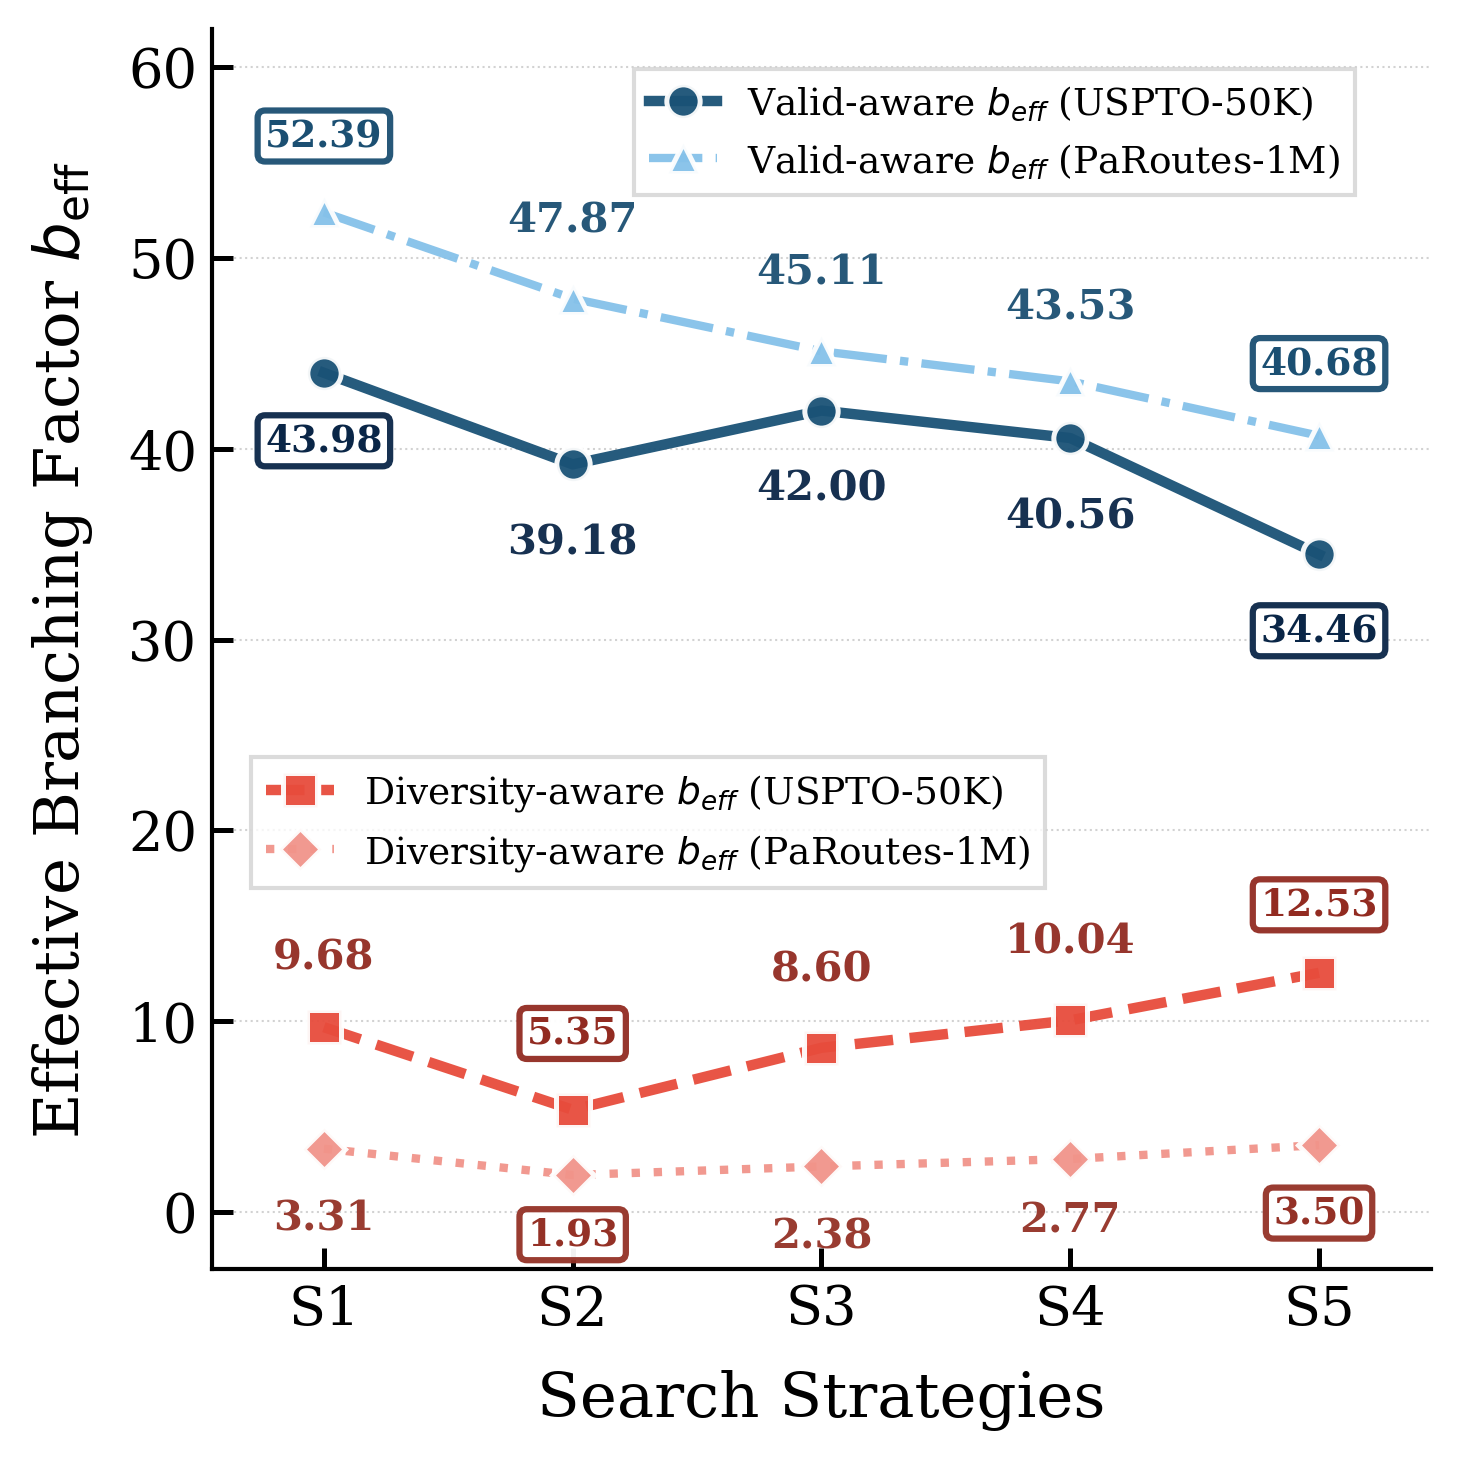

In [51]:
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# 数据
# -----------------------------
classes = ['S1', 'S2', 'S3', 'S4', 'S5']

valid_50k  = [43.98, 39.18, 42.0, 40.56, 34.46]
div_50k    = [9.68,  5.35,  8.60,  10.04, 12.53]
valid_400k = [52.39, 47.87, 45.11, 43.53, 40.68]
div_400k   = [3.31,  1.93,  2.38,  2.77,  3.50]

x = np.arange(len(classes))

# -----------------------------
# 期刊级绘图设置
# -----------------------------
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'axes.labelsize': 13,
    'axes.titlesize': 15,
    'legend.fontsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 1.0,
    'xtick.major.width': 1.0,
    'ytick.major.width': 1.0,
})

fig, ax = plt.subplots(figsize=(5, 5), dpi=300)

# ---------- 颜色 ----------
line_colors = {
    'valid_50k':  '#1A5276',
    'div_50k':    '#E74C3C',
    'valid_400k': '#85C1E9',
    'div_400k':   '#F1948A',
}
annotate_colors = {
    'valid_50k':  '#0A2647',
    'div_50k':    '#922B21',
    'valid_400k': '#1B4F72',
    'div_400k':   '#943126',
}

markers = ['o', 's', '^', 'D']
line_styles = ['-', '--', '-.', ':']
line_widths = [2.5, 2.5, 2.0, 2.0]
marker_sizes = [8, 8, 7, 7]


lines_data = [
    (valid_50k,  'Valid-aware $b_{eff}$',   'USPTO-50K',  line_colors['valid_50k'],  markers[0], line_styles[0], line_widths[0], marker_sizes[0]),
    (div_50k,    'Diversity-aware $b_{eff}$','USPTO-50K',  line_colors['div_50k'],    markers[1], line_styles[1], line_widths[1], marker_sizes[1]),
    (valid_400k, 'Valid-aware $b_{eff}$',    'PaRoutes-1M',line_colors['valid_400k'], markers[2], line_styles[2], line_widths[2], marker_sizes[2]),
    (div_400k,   'Diversity-aware $b_{eff}$','PaRoutes-1M',line_colors['div_400k'],   markers[3], line_styles[3], line_widths[3], marker_sizes[3]),
]

# ---------- 绘制折线，同时收集 handles/labels ----------
handles, labels = [], []
for data, base_label, dataset, color, marker, ls, lw, ms in lines_data:
    label = f'{base_label} ({dataset})'
    h, = ax.plot(
        x, data, label=label, color=color, marker=marker,
        linestyle=ls, linewidth=lw, markersize=ms,
        markeredgecolor='white', markeredgewidth=1.2,
        markerfacecolor=color, alpha=0.95, zorder=3,
    )
    handles.append(h)
    labels.append(label)

# ---------- 统一标注函数（逐点方向） ----------
def annotate_points(data, color_key, directions, offsets):
    color = annotate_colors[color_key]
    min_idx, max_idx = np.argmin(data), np.argmax(data)

    for i, val in enumerate(data):
        d = directions[i]
        off = offsets[i]
        y_off = off if d == 'up' else -off
        va = 'bottom' if d == 'up' else 'top'
        is_extreme = (i == min_idx or i == max_idx)

        if is_extreme:
            ax.annotate(
                f'{val:.2f}', xy=(x[i], val), xytext=(0, y_off),
                textcoords='offset points', ha='center', va=va,
                fontsize=9, fontweight='bold', color=color,
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                          edgecolor=color, linewidth=1.5, alpha=0.95),
                zorder=6,
            )
        else:
            ax.annotate(
                f'{val:.2f}', xy=(x[i], val), xytext=(0, y_off),
                textcoords='offset points', ha='center', va=va,
                fontsize=10, fontweight='bold', color=color,
                alpha=0.95, zorder=5,
            )

# ---------- 标注策略 ----------
annotate_points(valid_400k, 'valid_400k',
                directions=['up', 'up', 'up', 'up', 'up'],
                offsets=[14, 14, 14, 13, 13])

annotate_points(valid_50k, 'valid_50k',
                directions=['down', 'down', 'down', 'down', 'down'],
                offsets=[12, 14, 14, 14, 14])

annotate_points(div_50k, 'div_50k',
                directions=['up', 'up', 'up', 'up', 'up'],
                offsets=[12, 14, 14, 14, 12])

annotate_points(div_400k, 'div_400k',
                directions=['down', 'down', 'down', 'down', 'down'],
                offsets=[12, 10, 12, 10, 12])

# ---------- 坐标轴 ----------
ax.set_ylabel('Effective Branching Factor $b_{\\mathrm{eff}}$', fontsize=15, labelpad=8)
ax.set_xlabel('Search Strategies', fontsize=15, labelpad=8)
# ---------- 刻度 ----------
ax.set_xticks(x)
ax.set_xticklabels(classes, fontsize=13)  # 设置了两次
ax.tick_params(direction='in', length=5, width=1.2, labelsize=13)

ax.set_xlim(-0.45, len(classes) - 0.55)
ax.set_ylim(-3, 62)

# ---------- 网格 ----------
ax.yaxis.grid(True, linestyle=':', linewidth=0.5, alpha=0.35, color='gray')
ax.set_axisbelow(True)

# ---------- 边框 ----------
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.0)
ax.spines['bottom'].set_linewidth(1.0)


# ============================================================
# 图例拆成两块（按指标类型分组）
# 索引：0=valid_50k, 1=div_50k, 2=valid_400k, 3=div_400k
#   右上：两个 Valid-aware    → [0, 2]
#   左中：两个 Diversity-aware → [1, 3]
# ============================================================
idx_valid = [0, 2]   # valid_50k, valid_400k
idx_div   = [1, 3]   # div_50k, div_400k

# 第一块：右上（Valid-aware）
legend_valid = ax.legend(
    [handles[i] for i in idx_valid],
    [labels[i]  for i in idx_valid],
    frameon=True, fancybox=False, edgecolor='lightgray', facecolor='white',
    loc='upper right', bbox_to_anchor=(0.95, 0.98),
    ncol=1, columnspacing=1.0, handlelength=1.8,
    fontsize=9, borderaxespad=0.4,
)
ax.add_artist(legend_valid)   # 钉住第一块

# 第二块：左中（Diversity-aware）
legend_div = ax.legend(
    [handles[i] for i in idx_div],
    [labels[i]  for i in idx_div],
    frameon=True, fancybox=False, edgecolor='lightgray', facecolor='white',
    loc='center left', bbox_to_anchor=(0.02, 0.36),
    ncol=1, columnspacing=1.0, handlelength=1.8,
    fontsize=9, borderaxespad=0.4,
)

plt.tight_layout()

# plt.savefig('avg_beff_5x5.png', dpi=300, bbox_inches='tight')
# plt.savefig('avg_beff_5x5.pdf', bbox_inches='tight')
plt.show()

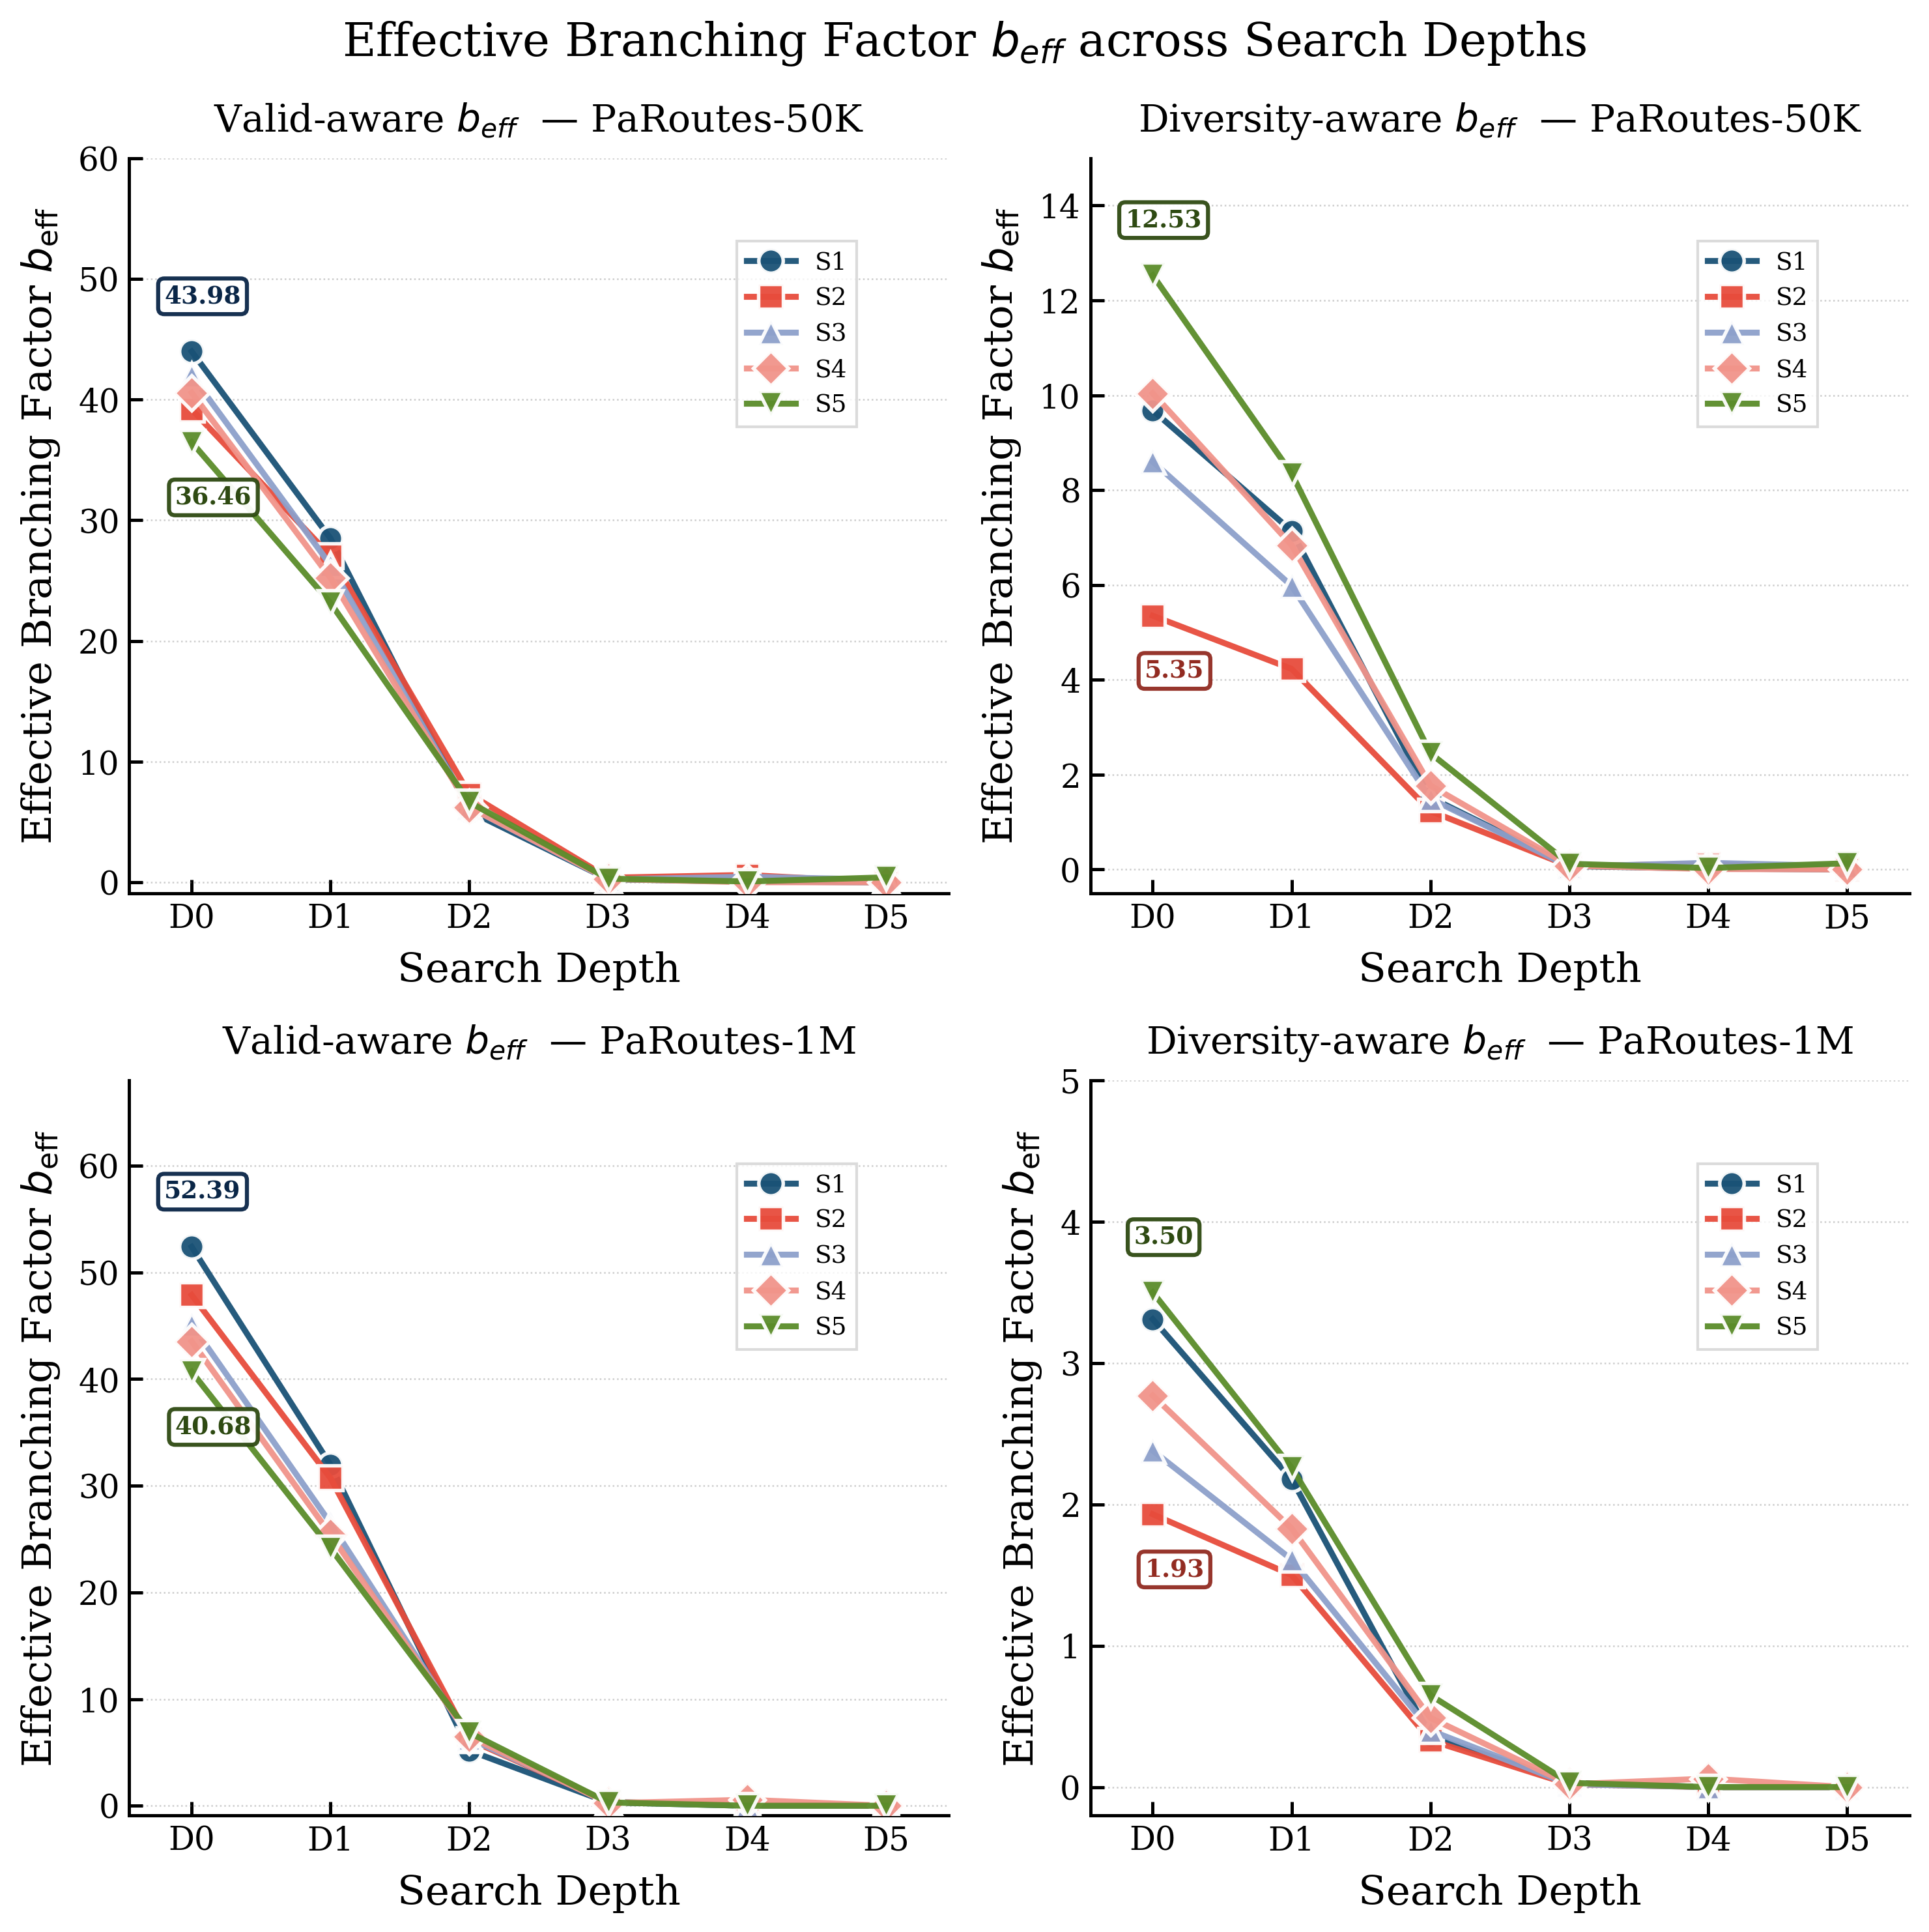

In [53]:
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# 数据
# -----------------------------
depths = np.array([0, 1, 2, 3, 4, 5])

data_50k_valid = {
    'S1':  [43.98, 28.49, 5.9,  0.25, 0.06, 0.0],
    'S2':  [39.18, 27.03, 7.31, 0.38, 0.61, 0.0],
    'S3':  [42.0,  26.28, 6.21, 0.24, 0.46, 0.22],
    'S4':  [40.56, 25.22, 6.22, 0.27, 0.01, 0.0],
    'S5':  [36.46, 23.14, 6.64, 0.3,  0.07, 0.41],
}
data_50k_div = {
    'S1':  [9.68, 7.14, 1.52, 0.07, 0.02, 0.0],
    'S2':  [5.35, 4.23, 1.23, 0.07, 0.12, 0.0],
    'S3':  [8.6,  5.98, 1.49, 0.06, 0.14, 0.07],
    'S4':  [10.04, 6.84, 1.77, 0.08, 0.01, 0.0],
    'S5':  [12.53, 8.35, 2.45, 0.12, 0.03, 0.13],
}
data_400k_valid = {
    'S1':  [52.39, 31.94, 5.17, 0.31, 0.0, 0.0],
    'S2':  [47.87, 30.71, 6.18, 0.36, 0.04, 0.0],
    'S3':  [45.11, 26.47, 6.29, 0.36, 0.0, 0.0],
    'S4':  [43.53, 25.42, 6.49, 0.24, 0.56, 0.0],
    'S5':  [40.68, 24.14, 6.85, 0.31, 0.0, 0.0],
}
data_400k_div = {
    'S1':  [3.31, 2.18, 0.36, 0.03, 0.0, 0.0],
    'S2':  [1.93, 1.5,  0.33, 0.02, 0.0, 0.0],
    'S3':  [2.38, 1.61, 0.4,  0.02, 0.0, 0.0],
    'S4':  [2.77, 1.83, 0.49, 0.02, 0.06, 0.0],
    'S5':  [3.5,  2.26, 0.65, 0.03, 0.0, 0.0],
}

# -----------------------------
# 期刊级绘图设置（与你微调后一致，仅微调统一），后面如果大小独立设置，这个会被覆盖
# -----------------------------
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'axes.labelsize': 13,
    'axes.titlesize': 15,
    'legend.fontsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 1.0,
    'xtick.major.width': 1.0,
    'ytick.major.width': 1.0,
})


class_colors  = ['#1A5276', '#E74C3C', '#8DA0CB', '#F1948A', '#5B8C2A']
class_markers = ['o', 's', '^', 'D', 'v']

# 对应线条的深色（用于标注文字/边框），与单图版 annotate_colors 一致的取色思路
annotate_colors = {
    'S1': '#0A2647',
    'S2': '#922B21',
    'S3': '#3D5A80',
    'S4': '#943126',
    'S5': '#2E4A12',
}

panels = [
    (data_50k_valid,  'Valid-aware $b_{eff}$  — PaRoutes-50K',  (-0.9, 60)),
    (data_50k_div,    'Diversity-aware $b_{eff}$  — PaRoutes-50K', (-0.5, 15)),
    (data_400k_valid, 'Valid-aware $b_{eff}$  — PaRoutes-1M',   (-0.9, 68)),
    (data_400k_div,   'Diversity-aware $b_{eff}$  — PaRoutes-1M', (-0.2, 5)),
]

fig, axes = plt.subplots(2, 2, figsize=(10, 10), dpi=300)

for ax, (data, title, ylim) in zip(axes.flat, panels):
    # ---- 先确定 D0 的最大/最小值对应的类（用于标注） ----
    d0_items = [(label, values[0]) for label, values in data.items() if values[0] is not None]
    d0_vals = [v for _, v in d0_items]
    max_idx_local = int(np.argmax(d0_vals))
    min_idx_local = int(np.argmin(d0_vals))
    max_class = d0_items[max_idx_local][0]
    min_class = d0_items[min_idx_local][0]
    max_val   = d0_items[max_idx_local][1]
    min_val   = d0_items[min_idx_local][1]

    # ---- 画线 ----
    for (label, values), color, marker in zip(data.items(), class_colors, class_markers):
        pts = [(d, v) for d, v in zip(depths, values) if v is not None]
        xd = [p[0] for p in pts]
        yd = [p[1] for p in pts]

        ax.plot(
            xd, yd,
            label=label,
            color=color,
            marker=marker,
            linewidth=2.2,
            markersize=9,
            markeredgecolor='white',
            markeredgewidth=1.3,
            markerfacecolor=color,
            alpha=0.95,
            zorder=3,
        )

    # ---- 标注 D0 的最大/最小值（带框） ----
    # 最大值：向上偏移；最小值：向下偏移；两侧略微左/右错开，避免与相邻点重合
    for (val, cls, direction) in [
        (max_val, max_class, 'up'),
        (min_val, min_class, 'down'),
    ]:
        c = annotate_colors[cls]
        offset_y = 16 if direction == 'up' else -16
        va = 'bottom' if direction == 'up' else 'top'
        # 向左/右微调 x 偏移（pt），最大点向左、最小点向右，避免重叠
        offset_x = 4 if direction == 'up' else 8

        ax.annotate(
            f'{val:.2f}',
            xy=(0, val),
            xytext=(offset_x, offset_y),
            textcoords='offset points',
            ha='center',
            va=va,
            fontsize=9,
            fontweight='bold',
            color=c,
            bbox=dict(
                boxstyle='round,pad=0.25',
                facecolor='white',
                edgecolor=c,
                linewidth=1.5,
                alpha=0.95,
            ),
            zorder=10,
        )

    # ---- 坐标轴/标题/刻度（保持你微调后的风格） ----
    ax.set_xlabel('Search Depth', fontsize=15, labelpad=6)
    ax.set_ylabel('Effective Branching Factor $b_{\\mathrm{eff}}$', fontsize=15, labelpad=6)
    ax.set_title(title, fontsize=14, pad=10)
    ax.set_xticks(depths)
    ax.set_xticklabels([f'D{d}' for d in depths])
    ax.tick_params(direction='in', length=5, width=1.2, labelsize=13)
    ax.set_xlim(-0.45, 5.45)
    ax.set_ylim(ylim)




    # 图例（D0 的标注在左上/左下，图例在右上，不冲突）
    ax.legend(
        frameon=True, fancybox=False, edgecolor='lightgray', facecolor='white',
        loc='upper right', bbox_to_anchor=(0.9, 0.9),
        fontsize=9, borderaxespad=0.4,
    )

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.2)
    ax.spines['bottom'].set_linewidth(1.2)
    ax.tick_params(direction='in', length=5, width=1.2, labelsize=12)
    ax.yaxis.grid(True, linestyle=':', linewidth=0.6, alpha=0.4, color='gray')
    ax.set_axisbelow(True)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.suptitle('Effective Branching Factor $b_{eff}$ across Search Depths',
             fontsize=17, y=0.985)

# plt.savefig('avg_b_eff_depth.png', dpi=300, bbox_inches='tight')
# plt.savefig('avg_b_eff_depth.pdf', bbox_inches='tight')
plt.show()

[1, 2, 3, 4, 5, 6]
[1, 2, 3, 4, 5, 6]
[1, 2, 3, 4, 5]
[1, 2, 3, 4, 5]


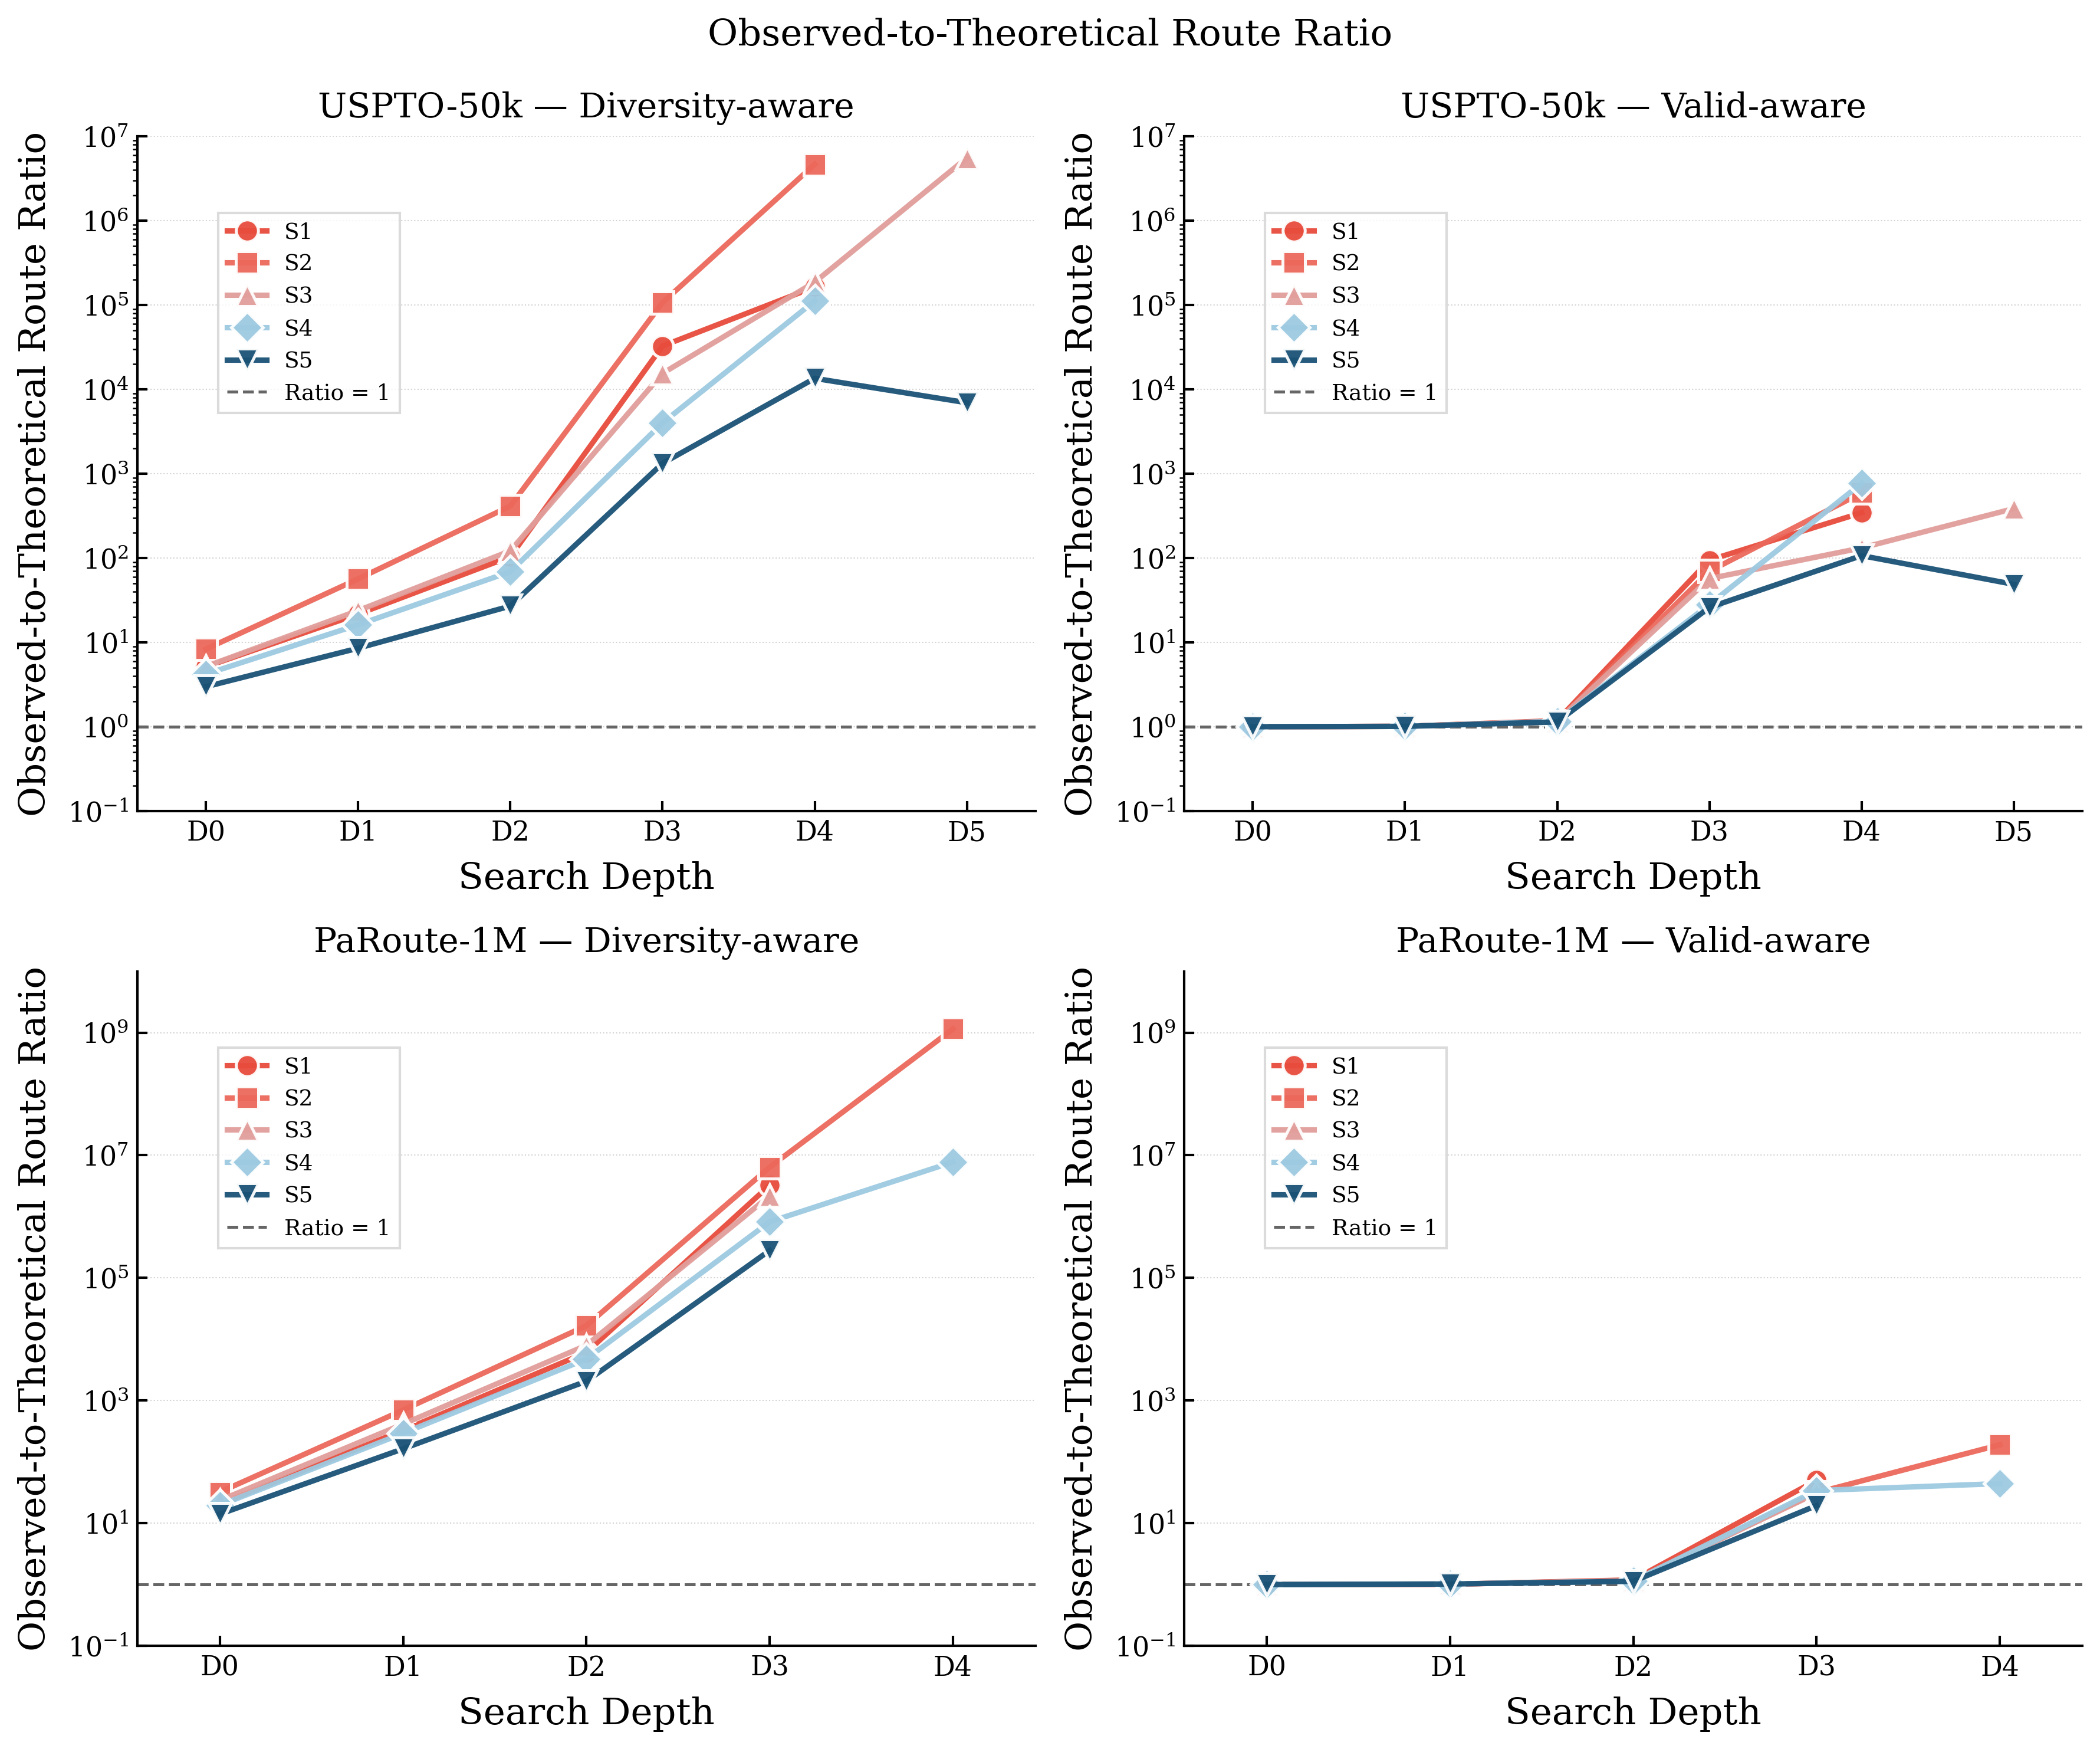

In [72]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# -----------------------------
# 数据
# -----------------------------
depths_5 = np.array([0, 1, 2, 3, 4, 5])
depths_4 = np.array([0, 1, 2, 3, 4])

data_4A = {
    'S1': [5.14, 21.62, 103.86, 32703.53, 164214.82, 0.0],
    'S2': [8.32, 56.63, 413.89, 106873.74, 4676816.51, 0.0],
    'S3': [5.18, 23.83, 121.68, 15493.36, 186912.94, 5583553.22],
    'S4': [4.2,  16.16, 68.86,  4003.44,  111973.9,   0.0],
    'S5': [2.98, 8.53,  26.96,  1327.63,  13541.82,   6949.74],
}
data_4B = {
    'S1': [1.0, 1.01, 1.18, 94.49, 345.08, 0.0],
    'S2': [1.0, 1.01, 1.16, 69.72, 593.85, 0.0],
    'S3': [1.0, 1.01, 1.16, 57.1,  131.91, 386.13],
    'S4': [1.0, 1.01, 1.16, 28.17, 769.89, 0.0],
    'S5': [1.0, 1.01, 1.14, 25.98, 106.93, 48.79],
}

data_4C = {
    'S1': [20.52, 326.83, 6100.11, 3244949.66, 0.0, 0.0],
    'S2': [32.15, 699.92, 16649.7, 6389167.01, 1144902758.5, 0.0],
    'S3': [23.56, 413.64, 7965.9,  2180058.8,  0.0, 0.0],
    'S4': [19.61, 292.84, 4755.23, 822269.36,  7766139.56,  0.0],
    'S5': [14.07, 163.63, 2065.23, 280796.9,   0.0, 0.0],
}
data_4D = {
    'S1': [1.0, 1.01, 1.19, 50.2,  0.0,   0.0],
    'S2': [1.0, 1.01, 1.17, 31.48, 190.16, 0.0],
    'S3': [1.0, 1.02, 1.15, 30.93, 0.0,    0.0],
    'S4': [1.0, 1.02, 1.14, 34.13, 44.27,  0.0],
    'S5': [1.0, 1.02, 1.13, 19.44, 0.0,    0.0],
}


# -----------------------------
# 期刊级绘图设置
# -----------------------------
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'axes.labelsize': 13,
    'axes.titlesize': 15,
    'legend.fontsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 1.0,
    'xtick.major.width': 1.0,
    'ytick.major.width': 1.0,
})

# -----------------------------
# 配色：每个子图内 S1→S5 用「红→蓝」跨色系渐变
# -----------------------------
class_depth = [0, 1, 3, 5, 10]
norm_depth = np.array(class_depth, dtype=float) / max(class_depth)

cmap_mixed = LinearSegmentedColormap.from_list(
    'mixed_red_blue',
    ['#E74C3C',  # S1 亮红
     '#F1948A',  # S2 粉红
     '#9ECAE1',  # S3 浅蓝（过渡）
     '#5DADE2',  # S4 天蓝
     '#1A5276']  # S5 深海军蓝
)
colors_mixed = [cmap_mixed(d) for d in norm_depth]

markers = ['o', 's', '^', 'D', 'v']

ref_line_color = '#666666'
ref_line_style = '--'
ref_line_width = 1.2

def truncate_at_zero(values):
    out = []
    for v in values:
        if v == 0.0:
            break
        out.append(v)
    return out

fig, axes = plt.subplots(2, 2, figsize=(12, 10), dpi=300)

subplots = [
    (axes[0, 0], data_4A, 'USPTO-50k — Diversity-aware', (0.1, 1e7)),
    (axes[0, 1], data_4B, 'USPTO-50k — Valid-aware',     (0.1, 1e7)),
    (axes[1, 0], data_4C, 'PaRoute-1M — Diversity-aware',  (0.1, 1e10)),
    (axes[1, 1], data_4D, 'PaRoute-1M — Valid-aware',      (0.1, 1e10)),
]

for ax, data, title, ylim in subplots:

    # ✅ 每个子图都用同一套"红→蓝"渐变
    for (label, values), color, marker in zip(data.items(), colors_mixed, markers):
        vals = truncate_at_zero(values)
        if len(vals) == 0:
            continue
        depths = np.arange(1, len(vals) + 1)

        ax.plot(
            depths, vals,
            label=label,
            color=color,
            marker=marker,
            linewidth=2.2,
            markersize=9,
            markeredgecolor='white',
            markeredgewidth=1.2,
            markerfacecolor=color,
            alpha=0.95,
            zorder=3,
        )

    all_depths = sorted(set(
        d for vals in data.values()
        for d in range(1, len(truncate_at_zero(vals)) + 1)
    ))

    print(all_depths)

    ax.axhline(
        y=1, color=ref_line_color, linestyle=ref_line_style,
        linewidth=ref_line_width, zorder=1, label='Ratio = 1',
    )

    ax.set_xlabel('Search Depth', fontsize=15, labelpad=6)
    ax.set_ylabel('Observed-to-Theoretical Route Ratio', fontsize=15, labelpad=6)
    ax.set_title(title, fontsize=14, pad=8)
    ax.set_xticks(all_depths)
    ax.set_xticklabels([f'D{d-1}' for d in all_depths], fontsize=13)
    ax.set_xlim(all_depths[0] - 0.45, all_depths[-1] + 0.45)

    ax.set_yscale('log')
    ax.set_ylim(ylim)

    ax.legend(
        frameon=True, fancybox=False, edgecolor='lightgray', facecolor='white',
        loc='upper left', bbox_to_anchor=(0.08, 0.9),
        ncol=1, columnspacing=1.0, handlelength=1.8,
        fontsize=9, borderaxespad=0.4,
    )

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.0)
    ax.spines['bottom'].set_linewidth(1.0)
    ax.tick_params(direction='in', length=4, width=1.0, labelsize=11)
    ax.yaxis.grid(True, linestyle=':', linewidth=0.5, alpha=0.35, color='gray')
    ax.set_axisbelow(True)

plt.tight_layout(rect=[0, 0, 1, 0.96])
fig.suptitle('Observed-to-Theoretical Route Ratio', fontsize=15, y=0.985)

# plt.savefig('figure4_Observed-to-Theoretical_Route_Ratio.png', dpi=300, bbox_inches='tight')
# plt.savefig('figure4_Observed-to-Theoretical_Route_Ratio.pdf', bbox_inches='tight')
plt.show()